# Persons Involved in the Group

The five students are:
- Student 1
- Student 2
- Student 3
- Student 4
- Student 5

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

torch.manual_seed(0)
rng = np.random.default_rng(0)  # fixed seeds: the notebook gives the same numbers at every run
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .3})

# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [2]:
# read data
daily_temp_brest = pd.read_csv('daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

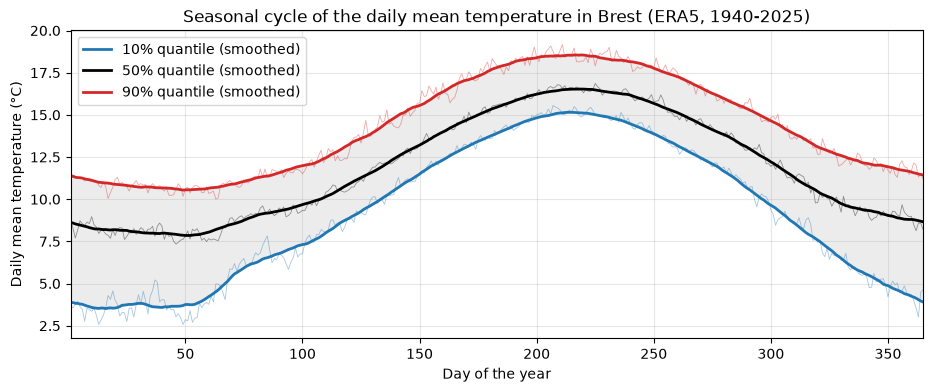

          q10    q50    q90
min       3.5    7.8   10.5
idxmin   16.0   50.0   49.0
max      15.2   16.5   18.6
idxmax  215.0  219.0  219.0


In [3]:
d = daily_temp_brest.assign(date=pd.to_datetime(daily_temp_brest.valid_time))
d = d[~((d.date.dt.month == 2) & (d.date.dt.day == 29))].copy()  # drop 29 February -> 365 days every year
d['doy'] = d.groupby(d.date.dt.year).cumcount() + 1               # day of year, from 1 to 365

# quantiles at 10%, 50%, 90% of the 86 values (1940-2025) available for each day of the year
q = d.groupby('doy')['mean'].quantile([.1, .5, .9]).unstack()
q.columns = ['q10', 'q50', 'q90']

# 1-month (31-day) centred rolling mean, made circular: 31 December is followed by 1 January
smooth = lambda s: pd.concat([s.iloc[-15:], s, s.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
qs = q.apply(smooth)

fig, ax = plt.subplots()
for c, col in zip(['q10', 'q50', 'q90'], ['tab:blue', 'k', 'tab:red']):
    ax.plot(q.index, q[c], color=col, lw=.6, alpha=.4)
    ax.plot(qs.index, qs[c], color=col, lw=2, label=f'{c[1:]}% quantile (smoothed)')
ax.fill_between(qs.index, qs.q10, qs.q90, color='grey', alpha=.15)
ax.set(xlabel='Day of the year', ylabel='Daily mean temperature (°C)', xlim=(1, 365),
       title='Seasonal cycle of the daily mean temperature in Brest (ERA5, 1940-2025)')
ax.legend()
plt.show()
print(qs.agg(['min', 'idxmin', 'max', 'idxmax']).round(1))

**Choices.** The 29 February is removed so that every year has exactly 365 days (it only concerns 22 days out of 31 412).
The smoothing window is 31 days, centred, and *circular*: to smooth the first days of January we use the last days of
December, because the seasonal cycle is periodic.

**Comment.** The three curves follow a smooth sinusoidal cycle. The coldest period is around mid-February (day ~50,
median ≈ 7.8 °C) and the warmest around early August (day ~219, median ≈ 16.5 °C): the annual amplitude of the median
is only ≈ 9 °C, and the maximum comes about 6 weeks after the summer solstice. This small amplitude and this delay are
the signature of the **oceanic climate** of Brest: the Atlantic Ocean stores heat in summer and releases it in winter.
The spread between the 10 % and 90 % quantiles is larger in winter (≈ 7 °C) than in summer (≈ 3.5 °C): in winter,
the temperature depends strongly on the wind direction (mild oceanic air vs. cold continental air), while summers are
more regular. The 90 % curve (between ≈ 10.5 °C in winter and ≈ 18.6 °C in summer) is the threshold used below to
detect heat waves.

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [4]:
MIN_DURATION = 3  # a heat wave = at least 3 consecutive hot days

d = d.join(qs, on='doy')
d['hot'] = d['mean'] > d.q90                      # hot day: above the smoothed 90% quantile of its day
d['anomaly'] = d['mean'] - d.q50                  # anomaly w.r.t. the "normal" day (smoothed median), in °C
d['run'] = (d.hot != d.hot.shift()).cumsum()      # same label for consecutive days with the same status

waves = (d[d.hot].groupby('run')
         .agg(start=('date', 'first'), duration=('hot', 'size'), intensity=('anomaly', 'mean'))
         .query('duration >= @MIN_DURATION')
         .assign(year=lambda w: w.start.dt.year, month=lambda w: w.start.dt.month)
         .reset_index(drop=True))

print(f'{len(waves)} heat waves of at least {MIN_DURATION} days between 1940 and 2025')
print('\nLongest:\n', waves.nlargest(5, 'duration').round({'intensity': 2}).to_string(index=False))
print('\nMost intense:\n', waves.nlargest(5, 'intensity').round({'intensity': 2}).to_string(index=False))

421 heat waves of at least 3 days between 1940 and 2025

Longest:
      start  duration  intensity  year  month
1955-08-16        14       4.11  1955      8
1976-08-13        14       3.38  1976      8
1975-07-28        11       3.63  1975      7
1945-04-11        10       4.64  1945      4
1947-08-12        10       4.63  1947      8

Most intense:
      start  duration  intensity  year  month
2022-07-16         3       7.69  2022      7
2000-06-16         3       6.69  2000      6
1976-06-25        10       6.51  1976      6
1940-06-03         6       6.10  1940      6
2017-05-24         3       6.03  2017      5


**Definitions.** Let $T_d$ be the daily mean temperature of day $d$ and $q_{p}(j)$ the smoothed quantile of its day
of the year $j$. A day is *hot* if $T_d>q_{90}(j)$. A heat wave is a maximal run of at least $L_{\min}=3$ consecutive
hot days (the slides speak of "several consecutive days"; 3 days is a usual convention). For a wave $W$:

$$
\text{duration}=|W|\ \text{(days)},\qquad
\text{intensity}=\frac{1}{|W|}\sum_{d\in W}\big(T_d-q_{50}(j_d)\big)\ \text{(°C)},
$$

i.e. the anomaly is measured with respect to the *normal* day (smoothed median).

**Comment.** We find 421 heat waves in 86 years (≈ 5 per year). The longest ones lasted 14 days (August 1955 and August
1976, the famous drought summer). The most intense one is **July 2022** (+7.7 °C above normal for 3 days), the heat
wave during which Brittany experienced record temperatures. Because the threshold depends on the day of the year,
the definition also detects mild spells in winter (e.g. April 1945): they are anomalies *for the season*, not hot days
in absolute terms.

Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

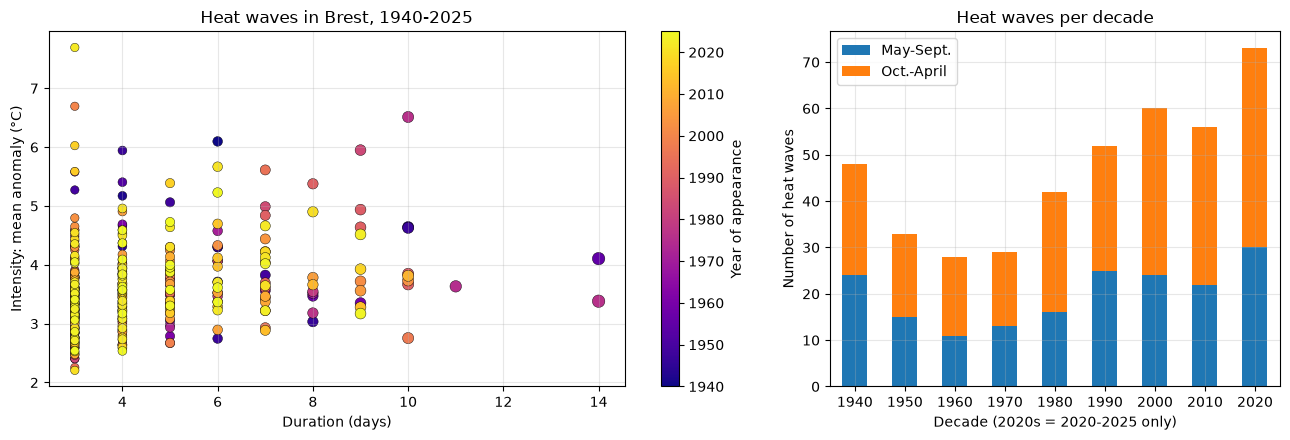

year       1940  1950  1960  1970  1980  1990  2000  2010  2020
duration   4.25  4.27  3.64  5.10  4.19  4.37  4.23  4.41  4.29
intensity  3.72  3.39  3.41  3.54  3.55  3.47  3.61  3.65  3.70


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
sc = a1.scatter(waves.duration, waves.intensity, c=waves.year, cmap='plasma', s=25 + 4 * waves.duration,
                edgecolor='k', lw=.3)
fig.colorbar(sc, ax=a1, label='Year of appearance')
a1.set(xlabel='Duration (days)', ylabel='Intensity: mean anomaly (°C)', title='Heat waves in Brest, 1940-2025')

decade = (waves.year // 10) * 10
summer = waves.month.between(5, 9)
pd.crosstab(decade, summer.map({True: 'May-Sept.', False: 'Oct.-April'})).plot.bar(stacked=True, ax=a2, rot=0)
a2.legend(title=None)
a2.set(xlabel='Decade (2020s = 2020-2025 only)', ylabel='Number of heat waves', title='Heat waves per decade')
plt.tight_layout()
plt.show()
print(waves.groupby(decade)[['duration', 'intensity']].mean().round(2).T)

**Comment.** Most heat waves are short (3 to 5 days) with an intensity between 2.5 and 5 °C; long waves (≥ 10 days) are
rare. There is no clear link between duration and intensity: the most intense waves are often short (a few days of
very hot continental air), while long waves are moderate. The colours show that the most intense short events
(top-left) are mainly recent (yellow: 2000s–2020s). The right panel shows the clearest signal: the **number** of heat
waves per decade decreased from the 1940s to the 1960s–1970s, then increased steadily, up to 73 waves in the 2020s,
which only contain 6 years (2020–2025). This is consistent with global warming since the 1980s. The mean duration and
intensity per decade, however, remain stable (≈ 4.3 days, ≈ 3.6 °C).

*Limit:* the quantiles are computed over the whole period 1940–2025. In a warming climate, the threshold is
"too low" for recent years and "too high" for old years, which mechanically creates more waves at the end of the
period. This is precisely the trend we want to show, but it should be kept in mind.

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [6]:
# read data
yearly_temp_brest = pd.read_csv('yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

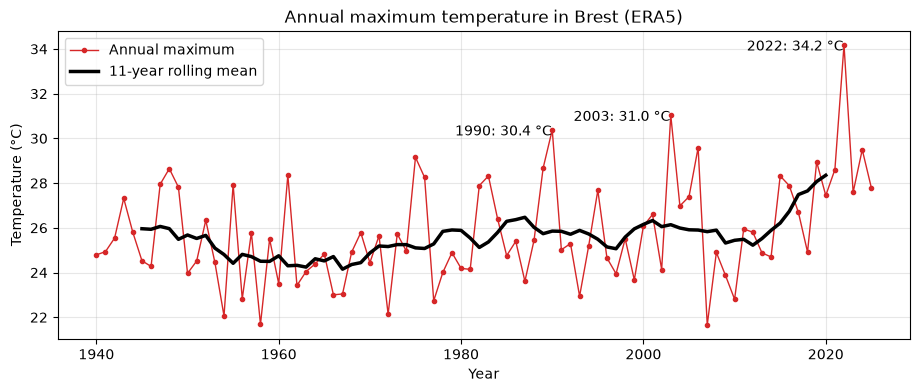

1940-1979: mean 25.10 °C, std 1.92 °C
1980-2025: mean 26.33 °C, std 2.43 °C


In [7]:
y = yearly_temp_brest.assign(year=pd.to_datetime(yearly_temp_brest.valid_time).dt.year)

fig, ax = plt.subplots()
ax.plot(y.year, y['max'], 'o-', ms=3, lw=1, color='tab:red', label='Annual maximum')
ax.plot(y.year, y['max'].rolling(11, center=True).mean(), lw=2.5, color='k', label='11-year rolling mean')
for _, r in y.nlargest(3, 'max').iterrows():
    ax.annotate(f"{r.year:.0f}: {r['max']:.1f} °C", (r.year, r['max']), xytext=(-70, -4), textcoords='offset points')
ax.set(xlabel='Year', ylabel='Temperature (°C)', title='Annual maximum temperature in Brest (ERA5)')
ax.legend()
plt.show()
for p in [(1940, 1979), (1980, 2025)]:
    s = y[y.year.between(*p)]
    print(f"{p[0]}-{p[1]}: mean {s['max'].mean():.2f} °C, std {s['max'].std():.2f} °C")

**Comment.** The annual maximum (the hottest moment of the year, in °C) fluctuates strongly from one year to the next
(between 21.7 °C and 34.2 °C), because it depends on the weather of a few days. The 11-year rolling mean is roughly flat
until the 1980s (≈ 25 °C) and then increases by about 1.5 to 2 °C. The mean was 25.1 °C over 1940–1979 and 26.3 °C over
1980–2025, and the year-to-year variability also increased (standard deviation 1.9 °C → 2.4 °C): recent decades have
both hotter and more variable extremes. The record of the series is 2022 (34.2 °C), clearly above the previous
records (2003: 31.0 °C; 1990: 30.4 °C). Note that ERA5 values are averages over a ≈ 9 km cell that includes some sea,
so they are lower than the peaks measured by a local weather station.

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

Pearson correlation between annual max temperature and CO2 (1940-2025):
                         CO2  ln(CO2)  ln(CO2/280)
T                      0.314    0.304        0.304
T, 5-yr rolling mean   0.490    0.474        0.474
T, 11-yr rolling mean  0.608    0.595        0.595
T, 21-yr rolling mean  0.828    0.823        0.823


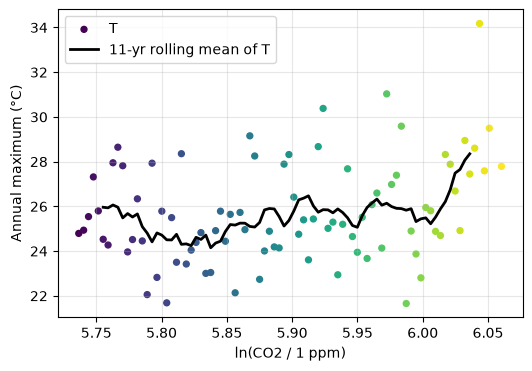

In [8]:
T_transforms = {'T': lambda s: s, **{f'T, {w}-yr rolling mean': (lambda w: lambda s: s.rolling(w, center=True).mean())(w)
                                       for w in (5, 11, 21)}}
C_transforms = {'CO2': y.co2, 'ln(CO2)': np.log(y.co2), 'ln(CO2/280)': np.log(y.co2 / 280)}

corr = pd.DataFrame({cn: {tn: f(y['max']).corr(c) for tn, f in T_transforms.items()}
                     for cn, c in C_transforms.items()})
print('Pearson correlation between annual max temperature and CO2 (1940-2025):')
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(np.log(y.co2), y['max'], c=y.year, cmap='viridis', s=18, label='T')
ax.plot(np.log(y.co2), y['max'].rolling(11, center=True).mean(), 'k', lw=2, label='11-yr rolling mean of T')
ax.set(xlabel='ln(CO2 / 1 ppm)', ylabel='Annual maximum (°C)')
ax.legend()
plt.show()

**Comment.** The raw correlation between the annual maximum and CO2 is weak, $r\approx0.31$: in a single year, the
weather noise dominates the climate signal. The logarithm of CO2 gives almost the same value ($r\approx0.30$), because
CO2 only varies from 310 to 428 ppm, a range where $\ln$ is almost linear (and $\ln(C/280)$ gives exactly the same $r$
as $\ln C$, since the Pearson correlation is invariant under affine transforms). Smoothing the temperature with a
rolling mean removes the year-to-year noise and increases the correlation a lot: $r=0.47$ (5 years), $0.60$ (11 years),
$0.82$ (21 years).

This high correlation does not mean that the annual maximum of a given year is predictable: it means that the
**mean level** of the extremes follows CO2, while the weather adds a large random part around it. This is exactly why
the forecast must be **probabilistic**: the model should predict how the *distribution* of the annual maximum moves
with CO2. We keep $\ln(C/C_0)$ as the covariate, because the radiative forcing of CO2 is logarithmic, which matters
when we extrapolate up to 946 ppm.

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [9]:
# read data
yearly_future_co2 = pd.read_csv('yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


## Our approach: a non-stationary GEV model, trained with PyTorch, with bootstrap Monte-Carlo

**Why a GEV distribution?** We want the distribution of an *annual maximum*, i.e. the maximum of 365 daily values.
The Fisher–Tippett–Gnedenko theorem (the "central limit theorem of extremes") states that, after normalisation,
the maximum of many random variables can only converge to one family of distributions: the
**Generalised Extreme Value** (GEV) law. Its cumulative distribution function is

$$
F(t;\mu,\sigma,\xi)=\exp\left\{-\left[1+\xi\,\frac{t-\mu}{\sigma}\right]^{-1/\xi}\right\},
\qquad 1+\xi\frac{t-\mu}{\sigma}>0,
$$

with a location $\mu$ (°C), a scale $\sigma>0$ (°C) and a shape $\xi$ (no unit). For temperature maxima, $\xi<0$:
the distribution has a finite upper bound $t_{\max}=\mu-\sigma/\xi$ (the atmosphere cannot heat up indefinitely).

**Conditioning on CO2.** The climate changes, so the law of year $t$ depends on the CO2 concentration $C_t$ (ppm).
The greenhouse effect of CO2 is logarithmic (the radiative forcing is $\Delta F \approx 5.35\,\ln(C/C_0)$ W/m²),
so the location moves linearly with $x_t=\ln(C_t/C_0)$, with $C_0=280$ ppm (pre-industrial level):

$$
T_t \mid C_t \sim \mathrm{GEV}\big(\mu_t,\ \sigma,\ \xi\big),\qquad \mu_t=\beta_0+\beta_1\,x_t,
\qquad \theta=(\beta_0,\beta_1,\log\sigma,\xi).
$$

$\beta_1$ (°C per unit of $\ln$ CO2) is the sensitivity of Brest's hottest day to CO2.

**Training (PyTorch).** The parameters minimise the negative log-likelihood on the observed years,
by gradient descent (Adam optimiser, automatic differentiation):

$$
\mathcal{L}(\theta)=\sum_{t}\left[\log\sigma+\left(1+\frac1\xi\right)\log z_t+z_t^{-1/\xi}\right],
\qquad z_t=1+\xi\,\frac{T_t-\mu_t}{\sigma},
$$

under two physical constraints, imposed at each gradient step: $\beta_1\ge 0$ (more CO2 cannot make the climate
colder) and $\xi\in[-0.5,-0.01]$ (bounded upper tail, as is standard for temperatures).

**Uncertainty on the parameters (bootstrap).** With only 86 years, $\theta$ is uncertain, and this uncertainty grows
when we extrapolate to 946 ppm. We therefore train $B=500$ models in parallel, each on a bootstrap sample of the years
(drawn with replacement), which gives $\theta^{(1)},\dots,\theta^{(B)}$. The predictive distribution is the mixture

$$
p(T\mid C)\approx\frac1B\sum_{b=1}^{B}\mathrm{GEV}\big(T;\ \beta_0^{(b)}+\beta_1^{(b)}\ln(C/C_0),\ \sigma^{(b)},\ \xi^{(b)}\big).
$$

**Monte-Carlo forecasts.** For each scenario we draw $N=10\,000$ trajectories 2026–2100: each trajectory picks one
model $b$ at random, then draws every year by inverting the CDF, with $U\sim\mathcal U(0,1)$:

$$
T=\mu+\frac{\sigma}{\xi}\Big[(-\ln U)^{-\xi}-1\Big].
$$

The output is not one value per year but an **ensemble of 10 000 possible futures**: any probability
(e.g. of exceeding 40 °C) is simply the fraction of members where the event happens.

**Why not a diffusion model or a deep network?** With 86 data points, a neural network with thousands of parameters would
overfit, and nothing guarantees a sensible behaviour at 946 ppm, far outside the training range. Our model keeps
the generative and Monte-Carlo spirit of modern probabilistic ML (PyTorch, gradient training, ensembles,
sampling) while having 4 parameters with a physical meaning and a form justified by extreme-value theory.

**Validation (out-of-sample).** Before using the model, we check it honestly: we train it on 1940–2000 only and predict
2001–2025 (a period with more CO2 than anything seen in training). The score is the CRPS
(Continuous Ranked Probability Score, in °C, lower is better), which compares a whole predicted distribution
to the observed value: $\mathrm{CRPS}(F,y)=\int\big(F(u)-\mathbf 1\{u\ge y\}\big)^2du
=\mathbb E|X-y|-\tfrac12\mathbb E|X-X'|$ with $X,X'\sim F$ independent.

In [10]:
C0 = 280.0  # pre-industrial CO2 (ppm)

def fit_gev(x, t, B=500, steps=3000):
    """Fit B GEV models (mu = b0 + b1 x) in parallel, each on a bootstrap sample of the years. Returns (B, 4)."""
    x, t = torch.tensor(x), torch.tensor(t)
    idx = torch.randint(len(t), (B, len(t)), generator=torch.Generator().manual_seed(0))
    idx[0] = torch.arange(len(t))                                     # model 0 = fit on the original data
    xb, tb = x[idx], t[idx]
    theta = torch.tensor([t.mean().item(), 0., t.std().log().item(), -.1], dtype=torch.float64).repeat(B, 1)
    theta.requires_grad_()
    opt = torch.optim.Adam([theta], lr=.02)
    for _ in range(steps):
        b0, b1, log_s, xi = theta.T[:, :, None]
        z = (1 + xi * (tb - b0 - b1 * xb) / log_s.exp()).clamp_min(1e-6)
        nll = (log_s + (1 + 1 / xi) * z.log() + z ** (-1 / xi)).sum()  # negative log-likelihood, all B models
        opt.zero_grad(); nll.backward(); opt.step()
        with torch.no_grad():
            theta[:, 1].clamp_(min=0)                                 # more CO2 cannot cool (b1 >= 0)
            theta[:, 3].clamp_(-.5, -.01)                             # bounded upper tail
    return theta.detach().numpy()

def sample_gev(theta, x, n=10_000):
    """n Monte-Carlo trajectories over the years x = ln(CO2/C0): each draws one bootstrap model. Returns (n, len(x))."""
    b0, b1, log_s, xi = theta[rng.integers(len(theta), size=n)].T[:, :, None]
    u = rng.random((n, len(x)))
    return b0 + b1 * x + np.exp(log_s) / xi * ((-np.log(u)) ** (-xi) - 1)

def crps(samples, obs):
    """Mean CRPS (°C): samples (n, n_years), obs (n_years,)."""
    s = np.sort(samples, axis=0)
    n = len(s)
    w = (2 * np.arange(1, n + 1) - n - 1) / n**2
    return np.mean(np.abs(s - obs).mean(axis=0) - w @ s)

# out-of-sample validation: train on 1940-2000, predict 2001-2025
x_all = np.log(y.co2.to_numpy() / C0)
train, test = y.year <= 2000, y.year > 2000
theta_val = fit_gev(x_all[train], y['max'][train].to_numpy())
b1, b0 = np.polyfit(x_all[train], y['max'][train], 1)              # baseline: linear trend + Gaussian noise
sd = np.std(y['max'][train] - b0 - b1 * x_all[train], ddof=2)
gauss = b0 + b1 * x_all[test] + sd * rng.standard_normal((10_000, test.sum()))
print(f"CRPS 2001-2025, GEV + bootstrap : {crps(sample_gev(theta_val, x_all[test]), y['max'][test].to_numpy()):.2f} °C")
print(f"CRPS 2001-2025, Gaussian linear : {crps(gauss, y['max'][test].to_numpy()):.2f} °C")
print(f"CRPS 2001-2025, constant 1940-2000 climatology: {crps(y['max'][train].to_numpy()[:, None], y['max'][test].to_numpy()):.2f} °C")

# final model: trained on all the data, 1940-2025
theta = fit_gev(x_all, y['max'].to_numpy())
print('\nFinal model (fit on 1940-2025): b0 = {:.2f} °C, b1 = {:.2f} °C, sigma = {:.2f} °C, xi = {:.2f}'
      .format(theta[0, 0], theta[0, 1], np.exp(theta[0, 2]), theta[0, 3]))
print('b1, 90% bootstrap interval: [{:.2f}, {:.2f}] °C per unit of ln(CO2)'.format(*np.percentile(theta[:, 1], [5, 95])))

CRPS 2001-2025, GEV + bootstrap : 1.66 °C
CRPS 2001-2025, Gaussian linear : 1.70 °C
CRPS 2001-2025, constant 1940-2000 climatology: 1.82 °C



Final model (fit on 1940-2025): b0 = 23.29 °C, b1 = 5.93 °C, sigma = 1.90 °C, xi = -0.11
b1, 90% bootstrap interval: [1.59, 10.39] °C per unit of ln(CO2)


**Comment on the validation.** Trained on 1940–2000 only, our model gets a CRPS of **1.66 °C** on 2001–2025, better than
a linear trend with Gaussian noise (1.70 °C) and than the constant climate of 1940–2000 (1.82 °C). The forecasts are
therefore better than simply assuming that the climate does not change. The gain over the Gaussian model is modest:
with 25 test years, the difference between two reasonable models is small.

**Comment on the parameters (fit on 1940–2025).** $\hat\beta_1\approx5.9$ °C per unit of $\ln$ CO2: from 1940 (310 ppm)
to 2025 (428 ppm), $\ln$ CO2 increased by 0.32, i.e. a shift of $\approx1.9$ °C of the location of the annual maximum.
The bootstrap interval of $\beta_1$ is wide ([1.6, 10.4] °C): the trend is clearly positive, but its size is uncertain
with 86 years, and this uncertainty is propagated to the forecasts. $\hat\sigma\approx1.9$ °C is the weather
variability, and $\hat\xi\approx-0.11<0$ confirms a bounded upper tail.

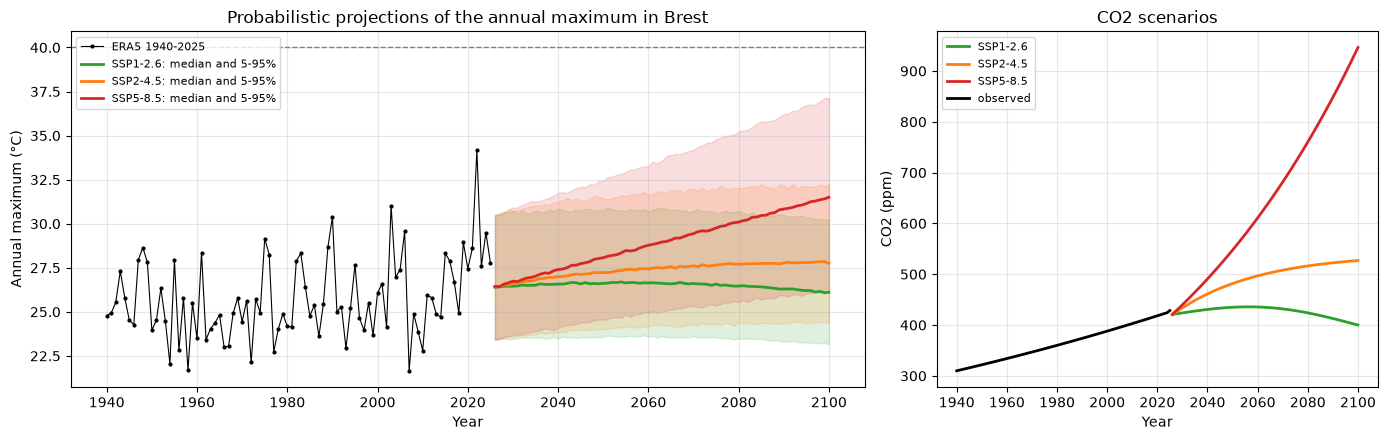

In [11]:
future = yearly_future_co2.assign(year=pd.to_datetime(yearly_future_co2.valid_time).dt.year)
SSP = {'ssp1-2.6': 'tab:green', 'ssp2-4.5': 'tab:orange', 'ssp5-8.5': 'tab:red'}
sims_max = {s: sample_gev(theta, np.log(future[s].to_numpy() / C0)) for s in SSP}   # (10 000, 75) per scenario

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.8, 1]})
a1.plot(y.year, y['max'], 'k.-', lw=.8, ms=4, label='ERA5 1940-2025')
for s, col in SSP.items():
    q5, q50, q95 = np.percentile(sims_max[s], [5, 50, 95], axis=0)
    a1.fill_between(future.year, q5, q95, color=col, alpha=.15)
    a1.plot(future.year, q50, color=col, lw=2, label=f'{s.upper()}: median and 5-95%')
    a2.plot(future.year, future[s], color=col, lw=2, label=s.upper())
a2.plot(y.year, y.co2, 'k', lw=2, label='observed')
a1.axhline(40, color='grey', ls='--', lw=1)
a1.set(xlabel='Year', ylabel='Annual maximum (°C)', title='Probabilistic projections of the annual maximum in Brest')
a2.set(xlabel='Year', ylabel='CO2 (ppm)', title='CO2 scenarios')
a1.legend(loc='upper left', fontsize=8); a2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Comment.** The three scenarios start from the same level in 2026 (median ≈ 26.5 °C) and diverge after 2040. Under
SSP1-2.6, CO2 peaks and decreases back to 400 ppm: the median annual maximum stabilises then slightly decreases
(≈ 26.1 °C in 2100). Under SSP2-4.5 it reaches ≈ 27.8 °C, and under SSP5-8.5 (946 ppm) ≈ 31.5 °C, i.e. a typical year
of 2100 would be as hot as the hottest years of the 20th century. The 5–95 % band is wide (≈ 7 to 11 °C) because a
single year's maximum depends on the weather; it widens with time under SSP5-8.5, because the uncertainty on the
CO2 sensitivity $\beta_1$ is multiplied by a larger CO2 increase.

Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

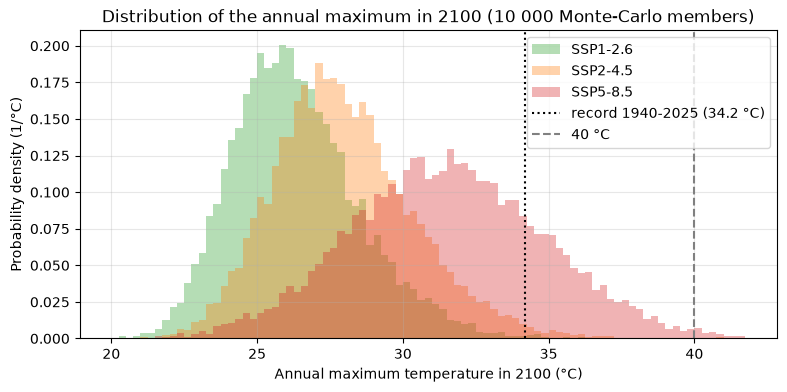

          CO2 2100 (ppm)  5% (°C)  50% (°C)  95% (°C)  P(year 2100 > 40 °C)  P(at least once in 2026-2100)
SSP1-2.6        400.0000  23.1557   26.1107   30.2905                0.0001                         0.0031
SSP2-4.5        526.9874  24.3773   27.7615   32.2539                0.0002                         0.0074
SSP5-8.5        946.2222  26.0934   31.5014   37.1399                0.0075                         0.0828

Median upper bound of the GEV in 2100 (°C): {'ssp1-2.6': np.float64(43.4), 'ssp2-4.5': np.float64(45.1), 'ssp5-8.5': np.float64(49.5)}


In [12]:
def summary_2100(sims, threshold, above=True):
    """Table of the 2100 distribution + probabilities of crossing a threshold (°C), for every scenario."""
    rows = {}
    for s, x in sims.items():
        hit = x > threshold if above else x < threshold
        rows[s.upper()] = {'CO2 2100 (ppm)': future[s].iloc[-1],
                           **{f'{p}% (°C)': np.percentile(x[:, -1], p) for p in (5, 50, 95)},
                           f'P(year 2100 {">" if above else "<"} {threshold} °C)': hit[:, -1].mean(),
                           'P(at least once in 2026-2100)': hit.any(axis=1).mean()}
    return pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(20, 42, .25)
for s, col in SSP.items():
    ax.hist(sims_max[s][:, -1], bins, density=True, histtype='stepfilled', alpha=.35, color=col, label=s.upper())
ax.axvline(y['max'].max(), color='k', ls=':', label=f"record 1940-2025 ({y['max'].max():.1f} °C)")
ax.axvline(40, color='grey', ls='--', label='40 °C')
ax.set(xlabel='Annual maximum temperature in 2100 (°C)', ylabel='Probability density (1/°C)',
       title='Distribution of the annual maximum in 2100 (10 000 Monte-Carlo members)')
ax.legend()
plt.show()

x2100 = np.log(future[list(SSP)].iloc[-1].to_numpy() / C0)
upper_bound = theta[:, :1] + theta[:, 1:2] * x2100 - np.exp(theta[:, 2:3]) / theta[:, 3:4]  # mu - sigma/xi, (B, 3)
print(summary_2100(sims_max, 40).round(4).to_string())
print('\nMedian upper bound of the GEV in 2100 (°C):', dict(zip(SSP, np.median(upper_bound, axis=0).round(1))))

**Answer: probability of exceeding 40 °C in Brest.** The question can be read in two ways, so we give both:

| Scenario | CO2 2100 | median 2100 | P(year 2100 > 40 °C) | P(at least one year > 40 °C in 2026–2100) |
|---|---|---|---|---|
| SSP1-2.6 | 400 ppm | 26.1 °C | ≈ 0.01 % | ≈ 0.3 % |
| SSP2-4.5 | 527 ppm | 27.8 °C | ≈ 0.02 % | ≈ 0.7 % |
| SSP5-8.5 | 946 ppm | 31.5 °C | ≈ 0.75 % | ≈ 8 % |

**Comment.** In the ERA5 data, exceeding 40 °C in Brest remains very unlikely in a given year, even in 2100 under the
worst scenario (< 1 %). But over the 75 years until 2100, the risk accumulates: under SSP5-8.5, there is about
**1 chance in 12** that at least one year exceeds 40 °C, against less than 1 % under SSP1-2.6. The choice of the
scenario, i.e. of the emissions, multiplies this risk by more than 20. With the fitted $\xi<0$, the GEV has a finite upper
bound $\mu-\sigma/\xi$ (median ≈ 43 °C for SSP1-2.6 and ≈ 50 °C for SSP5-8.5): 40 °C is physically possible in all
scenarios, but it lies far in the tail.

**Limits.** (i) The data are ERA5 cell averages (≈ 9 km, partly over the sea), which smooth the local peaks: a
weather station in Brest can be several degrees hotter than the ERA5 cell, so these probabilities concern the ERA5
variable and underestimate the risk for a station. (ii) The model only knows CO2: it ignores aerosols, changes in
atmospheric circulation or in soil moisture, which can amplify heat waves. (iii) 946 ppm is far outside the
observed range (310–428 ppm): the linear relation in $\ln$ CO2 is an extrapolation, partly controlled by the
bootstrap uncertainty. (iv) Probabilities below 0.1 % are estimated with only a few of the 10 000 members and
are therefore only orders of magnitude.

Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).

CRPS 2001-2025 (min), trained on 1940-2000: 1.09 °C


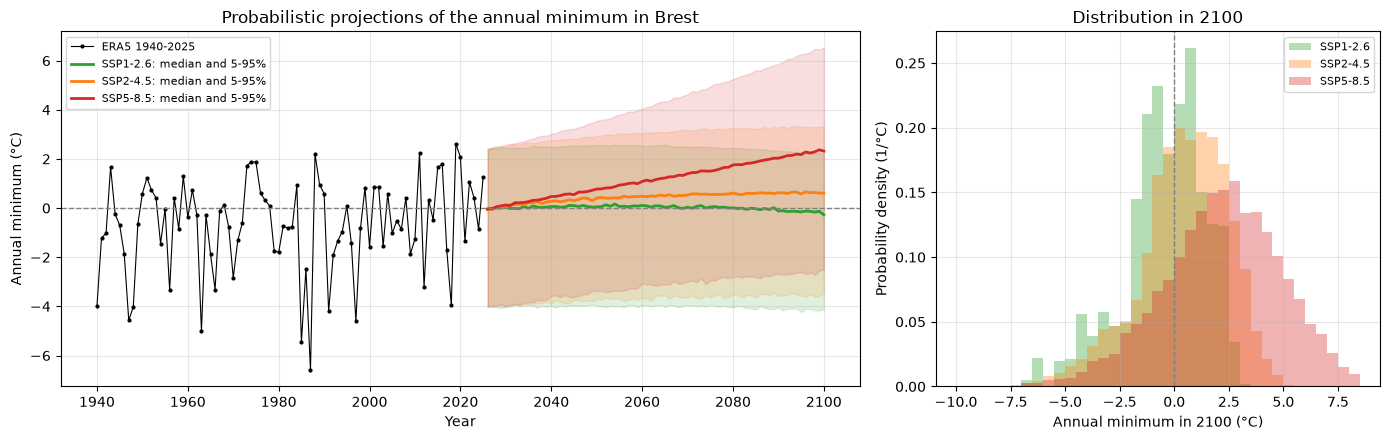

Pearson correlation of the annual minimum with ln(CO2): 0.15
Observed: 60% of the years 1940-2025 had a minimum below 0 °C
          CO2 2100 (ppm)  5% (°C)  50% (°C)  95% (°C)  P(year 2100 < 0 °C)  P(at least once in 2026-2100)
SSP1-2.6         400.000   -4.125    -0.276     2.215                0.542                            1.0
SSP2-4.5         526.987   -3.428     0.610     3.332                0.378                            1.0
SSP5-8.5         946.222   -2.493     2.319     6.536                0.200                            1.0


In [13]:
# Different approach for the minima: linear trend in ln(CO2) + non-parametric Monte-Carlo
# (residuals resampled from the observed years, regression refitted on bootstrap samples of the years)
def fit_resample(x, t, B=500):
    fits = []
    for b in range(B):
        i = rng.integers(len(t), size=len(t)) if b else np.arange(len(t))
        slope, icpt = np.polyfit(x[i], t[i], 1)
        fits.append((icpt, slope, t[i] - icpt - slope * x[i]))
    return fits

def sample_resample(fits, x, n=10_000):
    out = np.empty((n, len(x)))
    for k, b in enumerate(rng.integers(len(fits), size=n)):
        icpt, slope, res = fits[b]
        out[k] = icpt + slope * x + rng.choice(res, size=len(x))
    return out

val = fit_resample(x_all[train], y['min'][train].to_numpy())
print(f"CRPS 2001-2025 (min), trained on 1940-2000: {crps(sample_resample(val, x_all[test]), y['min'][test].to_numpy()):.2f} °C")
fits_min = fit_resample(x_all, y['min'].to_numpy())
sims_min = {s: sample_resample(fits_min, np.log(future[s].to_numpy() / C0)) for s in SSP}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.8, 1]})
a1.plot(y.year, y['min'], 'k.-', lw=.8, ms=4, label='ERA5 1940-2025')
for s, col in SSP.items():
    q5, q50, q95 = np.percentile(sims_min[s], [5, 50, 95], axis=0)
    a1.fill_between(future.year, q5, q95, color=col, alpha=.15)
    a1.plot(future.year, q50, color=col, lw=2, label=f'{s.upper()}: median and 5-95%')
    a2.hist(sims_min[s][:, -1], np.arange(-10, 9, .5), density=True, histtype='stepfilled', alpha=.35, color=col,
            label=s.upper())
a1.axhline(0, color='grey', ls='--', lw=1)
a2.axvline(0, color='grey', ls='--', lw=1)
a1.set(xlabel='Year', ylabel='Annual minimum (°C)', title='Probabilistic projections of the annual minimum in Brest')
a2.set(xlabel='Annual minimum in 2100 (°C)', ylabel='Probability density (1/°C)', title='Distribution in 2100')
a1.legend(loc='upper left', fontsize=8); a2.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Pearson correlation of the annual minimum with ln(CO2): {:.2f}'.format(y['min'].corr(np.log(y.co2))))
print(f"Observed: {(y['min'] < 0).mean():.0%} of the years 1940-2025 had a minimum below 0 °C")
print(summary_2100(sims_min, 0, above=False).round(3).to_string())

**Approach for the minima (different and non-parametric).** We keep a linear trend in $\ln$ CO2 fitted by least squares,
but no distribution is assumed for the noise: each Monte-Carlo member uses the regression fitted on a bootstrap
sample of the years, and adds residuals drawn from the observed residuals of that fit (residual bootstrap). The
predictive distribution is therefore built only from the observed anomalies.

**Comment.** The annual minimum (coldest moment of the year) is much less correlated with CO2 than the maximum
($r\approx0.15$): it is dominated by rare cold spells with continental air (1985, 1987 at −6.6 °C). Validated on
2001–2025 after training on 1940–2000, this approach gets a CRPS of 1.09 °C, close to the Gaussian baseline (1.06 °C):
the minima are hard to predict, and most of their variance is weather. In 2100 the median minimum is ≈ −0.3 °C (SSP1-2.6),
≈ +0.6 °C (SSP2-4.5) and ≈ +2.3 °C (SSP5-8.5). Over 1940–2025, 60 % of the years went below 0 °C; in 2100 this
probability falls to ≈ 54 %, 38 % and 20 % respectively: under SSP5-8.5, four years out of five would have no frost
at all in Brest. Frost does not disappear, though: over 2026–2100 every trajectory has at least one year below 0 °C.
The histograms are spiky because the noise is resampled among only 86 observed residuals.

# Conclusion

- **Past (Part 1).** Brest has a mild oceanic seasonal cycle (≈ 9 °C amplitude of the median). Heat waves, defined
  relative to the season, became much more frequent since the 1980s (73 waves in 2020–2025 alone), and the most intense
  one is July 2022.
- **Future (Part 2).** The annual maximum depends on CO2 through a weak but robust link (correlation 0.31 raw,
  0.82 after 21-year smoothing). A non-stationary GEV model trained with PyTorch, with bootstrap Monte-Carlo, beats a
  Gaussian baseline out of sample (CRPS 1.66 °C vs 1.70 °C). In 2100, the median annual maximum goes from ≈ 26 °C
  (SSP1-2.6) to ≈ 31.5 °C (SSP5-8.5). Exceeding 40 °C in a given year stays below 1 %, but the probability of at least
  one such year before 2100 reaches ≈ 8 % under SSP5-8.5, against ≈ 0.3 % under SSP1-2.6.
- **Main message.** The emission scenario strongly controls the risk of extreme heat in Brest, and the uncertainty
  (weather + model) must always be given with the forecast.